# Parcial 3 - Rodrigo Daniel Salazar Díaz

In [1]:
import numpy as np
import pandas as pd
import networkx as nx
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt
from modulo import *

In [2]:
e3 = pd.read_excel(r"C:\Users\Juan\Documents\GitHub\Neurociencias-2026-1\S03_datasets\eeg-motor-movementimagery_Ensayo_03.xlsx", sheet_name = None, index_col = 0)
e4 = pd.read_excel(r"C:\Users\Juan\Documents\GitHub\Neurociencias-2026-1\S03_datasets\eeg-motor-movementimagery_Ensayo_04.xlsx", sheet_name = None, index_col = 0)
e5 = pd.read_excel(r"C:\Users\Juan\Documents\GitHub\Neurociencias-2026-1\S03_datasets\eeg-motor-movementimagery_Ensayo_05.xlsx", sheet_name = None, index_col = 0)
e6 = pd.read_excel(r"C:\Users\Juan\Documents\GitHub\Neurociencias-2026-1\S03_datasets\eeg-motor-movementimagery_Ensayo_06.xlsx", sheet_name = None, index_col = 0)

coord = pd.read_csv(r"C:\Users\Juan\Documents\GitHub\Neurociencias-2026-1\S03_datasets\MI_coordinates.csv")

coord.set_index("canal", drop=True, inplace=True)

%matplotlib widget

# Ensayo 3

C:\Users\Juan\Documents\GitHub\Neurociencias-2026-1\S06_proyecto\modulo.py:79: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  estadisticos = estadisticos.applymap(lambda x: f"{x:.5f}" if isinstance(x,(float,int)) else x)


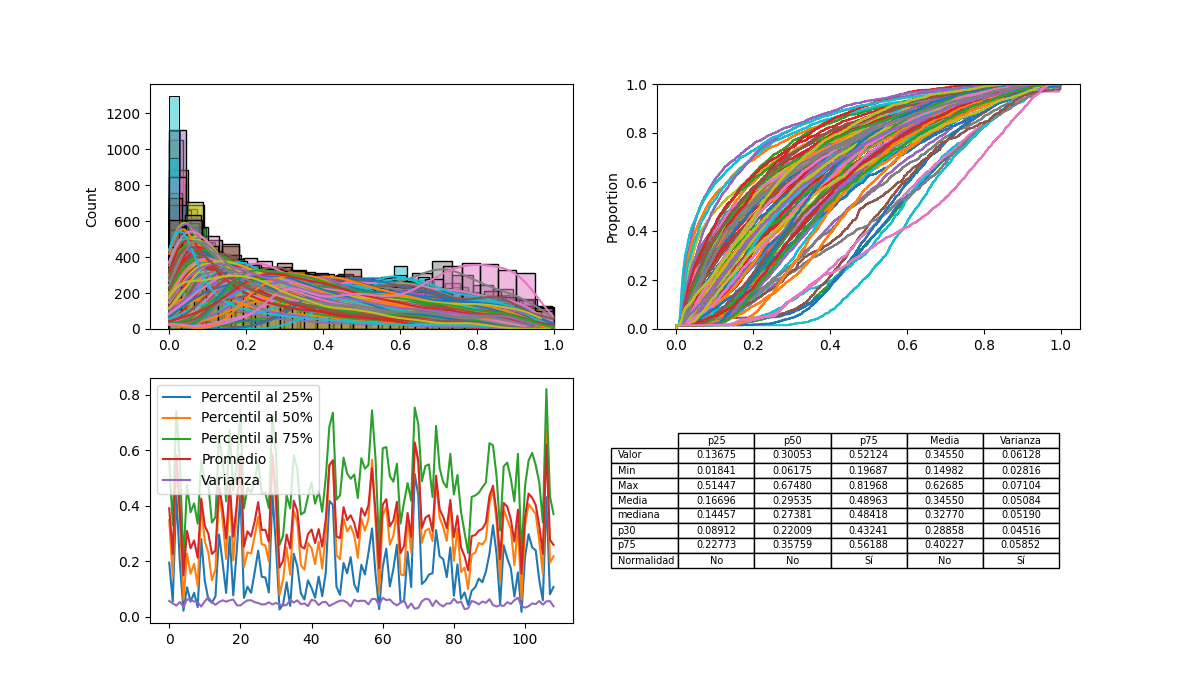

In [3]:
ensayo3 = lista_dfs(e3)
estadisticos_df(ensayo3)

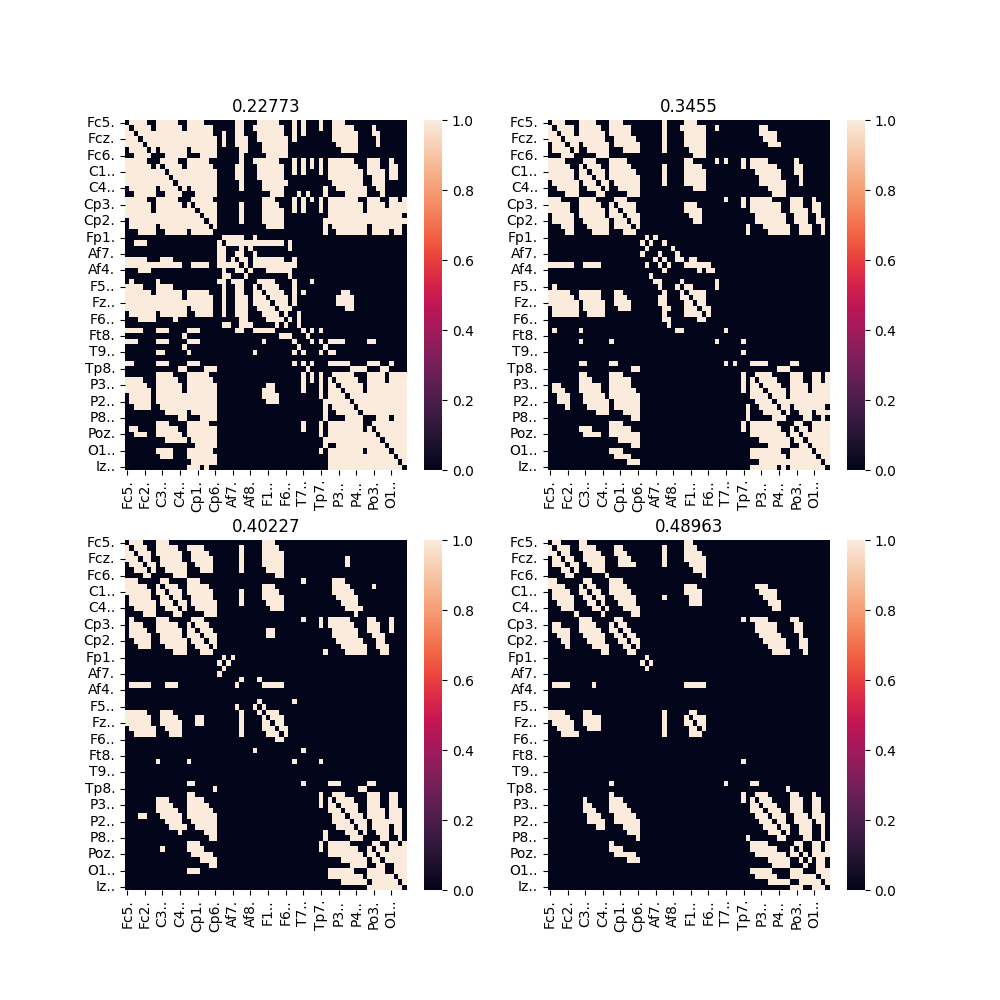

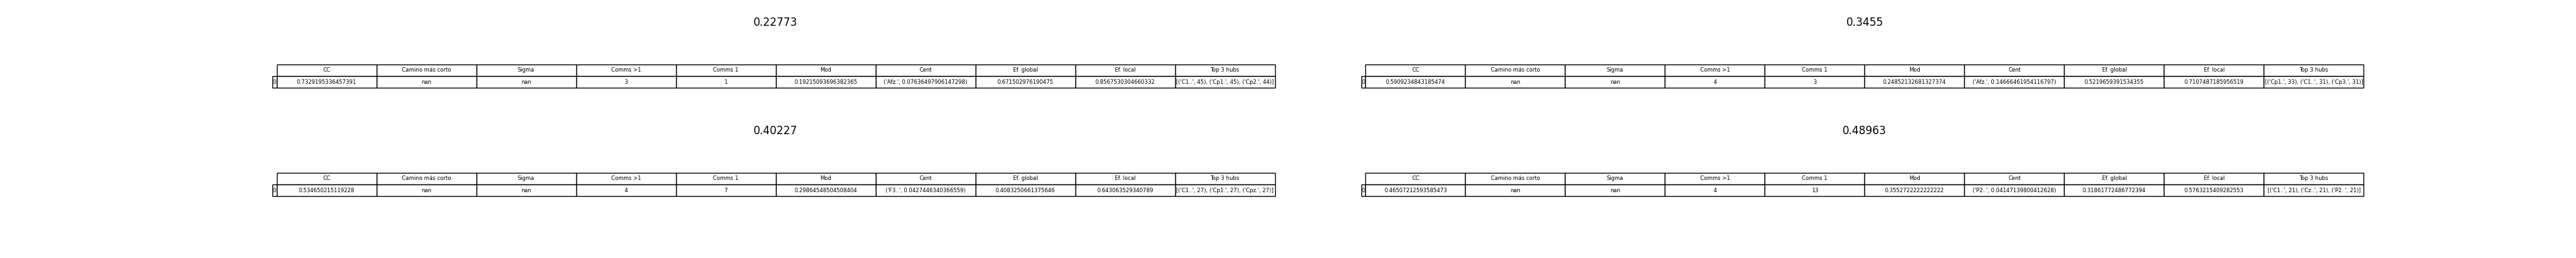

In [11]:
#Opciones de umbral: p75 de p25, media, p75 de la media, media de la p75

umbrales = [0.22773, 0.3455, 0.40227, 0.48963]
fig2 = plt.figure(figsize=(10,10))
axes = [fig2.add_subplot(2, 2, 1),
        fig2.add_subplot(2, 2, 2),
       fig2.add_subplot(2, 2, 3),
       fig2.add_subplot(2, 2, 4)]
i = 0
fig3, axes3 = plt.subplots(2,2, figsize=(40,4))
for umbral in umbrales:
    ensayo = capsula(ensayo3,umbral,0.75)
    sns.heatmap(ensayo, ax = axes[i])
    axes[i].set_title(str(umbral))
    i += 1

posiciones = [(0,0),(0,1),(1,0),(1,1)]
for umbral, (j,k) in zip(umbrales,posiciones):
    ensayo = capsula(ensayo3,umbral,0.75)
    (df_m, clust_coeff_, path_length_, small_world_sigma_, communities_, 
    modularity_, betwenness_, global_eff_, local_eff_, degree_dict_) = metricas(ensayo)
    axes3[j][k].axis('off')  # desactiva los ejes
    tabla = axes3[j][k].table(
        cellText=df_m.values,
        rowLabels=df_m.index,
        colLabels=df_m.columns,
        cellLoc='center',
        loc='center'
    )
    tabla.auto_set_font_size(False)
    tabla.set_fontsize(6)
    tabla.scale(1.1, 1.1)
    axes3[j][k].set_title(str(umbral))

### Umbral - Ensayo 3
Analizando los mapas de calor, número de comunidades, cantidad de nodo en esas comunidades, y la distribución topográfica de las conexiones se eligió el **percentil 75 de la media** como el umbral más adecuado para el **ensayo 3**. Esto es porque se busca el umbral que no pierda información, que preserve las características esperadas de conectividad y reduzca el ruido (conexiones poco significativas). 


Se optó por este valor ya que es el umbral que más información mantiene y mantiene un número contenido de comunidades. Con este umbral **(0.40227)** se observan muy claramente una comunidad o **red precentral(azul)** y una **postcentral(rojo)** y una pequeña red **precentral izquierda (verde)**.

El surco central es una fisura que divide longitudinalmente al cerebro en dos mitades. El giro precentral es una sección de la corteza que incluye, principalmente, a la corteza motora (encargada de iniciar el movimiento) mientras que el giro post central incluye la corteza somatosensorial (que recibe información de la posición y tacto sobre el cuerpo). 

Este umbral hace sentido ya que en la **red postcentral** que aparece se observa una muy alta conexión de áreas occipitales (de procesamiento visual), entre ellas, y con áreas parietales (corteza somatosensorial). Esto se intuye como la **retroalimentación visual del movimiento**, mientras que en la **red precentral** se conectan áreas frontales (toma de decisiones) y áreas precentrales (corteza motora), que se asume es por la **ejecución del movimiento**. Se observa además una **pequeña comunidad en la parte precentral izquierda (verde)**, esto **podría** ser indicativo de que **el grueso de los sujetos eran diestros** y hay conexiones más fuertes del lado izquierdo de la corteza motora (que controla el lado derecho del cuerpo) que del lado contrario.

### Gráficas de Ensayo 3 con el umbral elegido (0.40227)

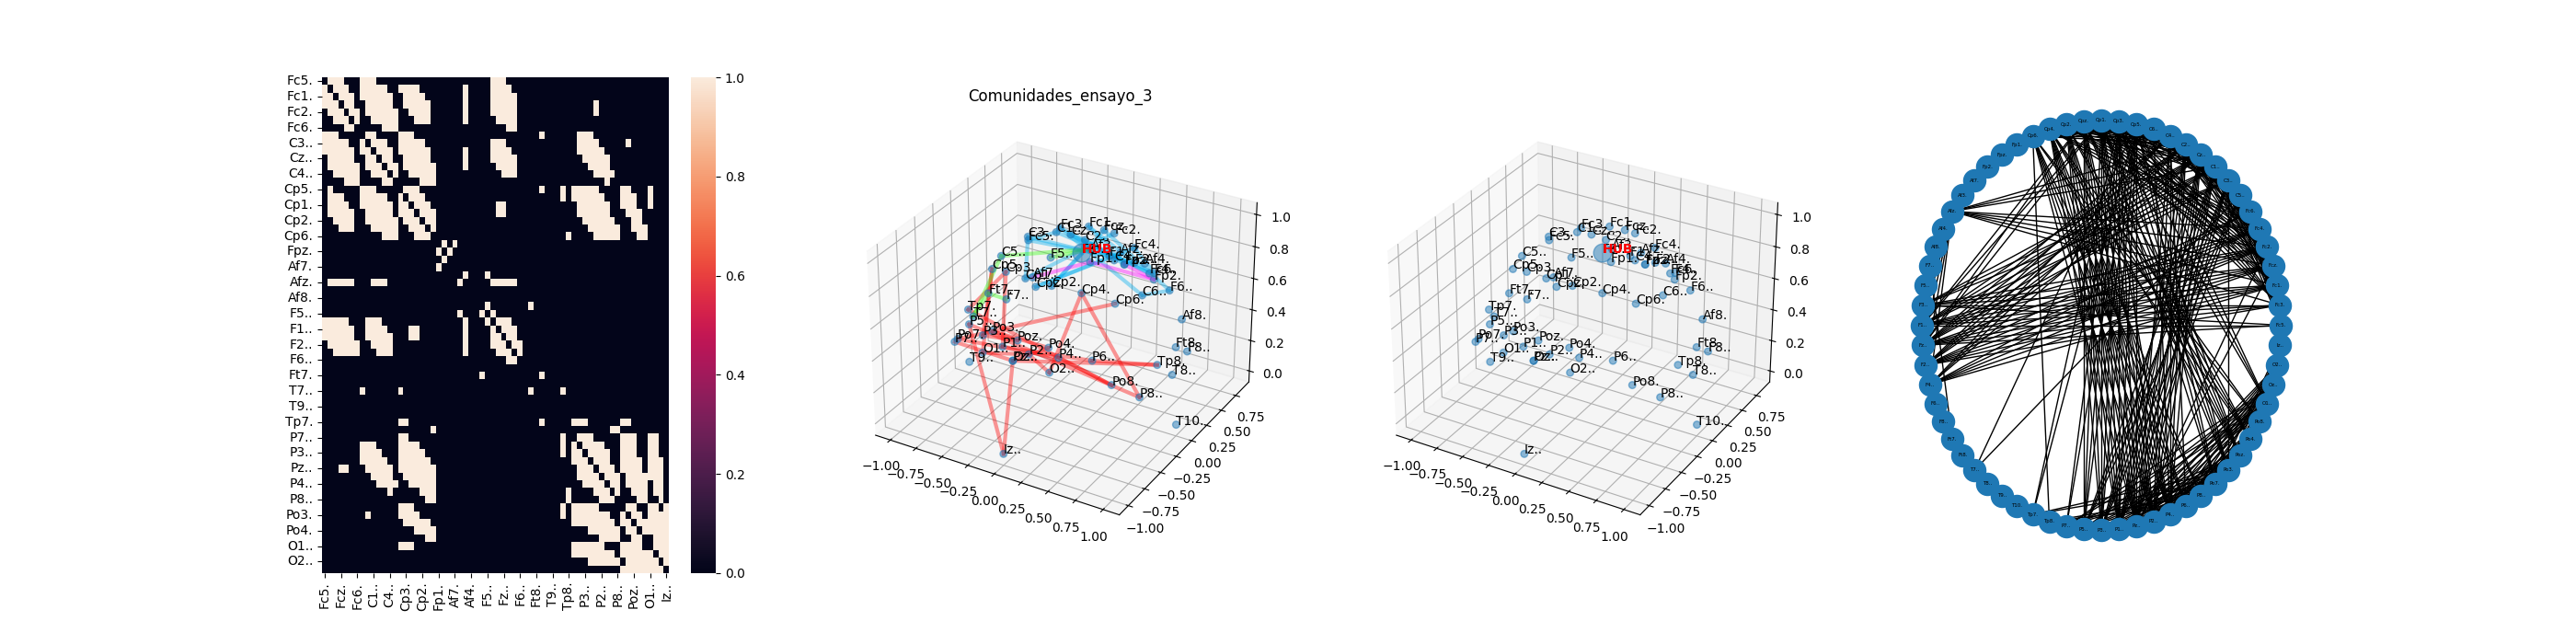

In [22]:
ensayo3_f = capsula(ensayo3,0.40227,0.75)

(df_m, clust_coeff_, path_length_, small_world_sigma_, communities_3, 
    modularity_, betwenness_3, global_eff_, local_eff_, degree_dict_) = metricas(ensayo3_f)

fig = plt.figure(figsize=(28,7))
axes = [fig.add_subplot(1, 4, 1),
        fig.add_subplot(1, 4, 2, projection='3d'),
       fig.add_subplot(1, 4, 3, projection='3d'),
       fig.add_subplot(1, 4, 4)]
hub3 = betwenness_3[0]
sns.heatmap(ensayo3_f, ax = axes[0])
grafcomm(communities_3, hub3, coord, axes[1])
graf3d(hub3, coord, axes[2])
graf2d(ensayo3_f, axes[3])

# Ensayo 4

C:\Users\Juan\Documents\GitHub\Neurociencias-2026-1\S06_proyecto\modulo.py:79: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  estadisticos = estadisticos.applymap(lambda x: f"{x:.5f}" if isinstance(x,(float,int)) else x)


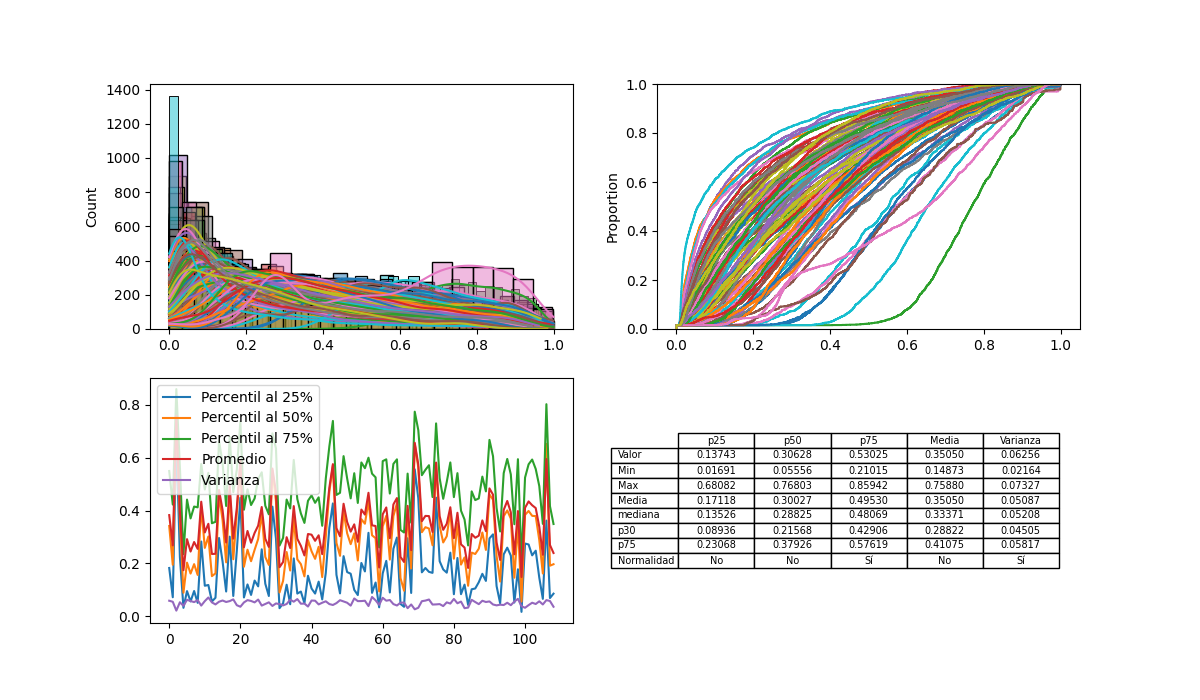

In [24]:
ensayo4 = lista_dfs(e4)
estadisticos_df(ensayo4)

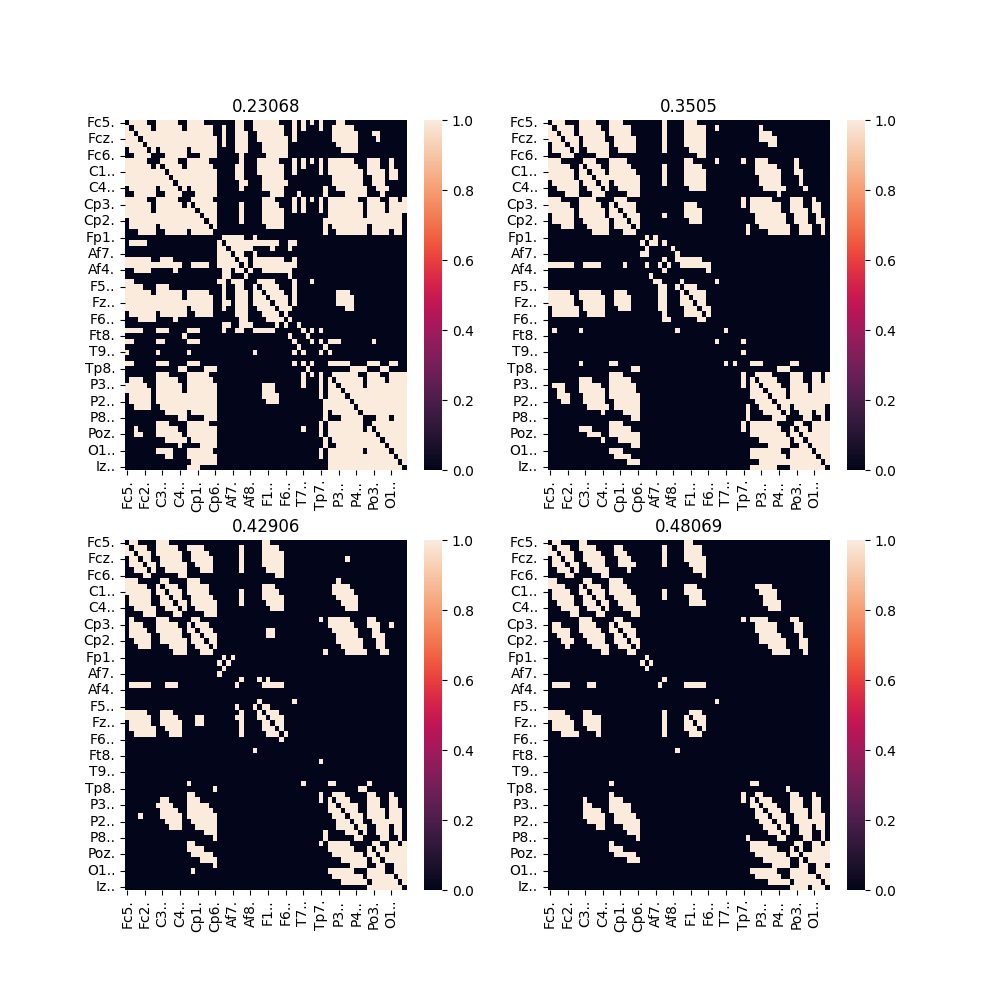

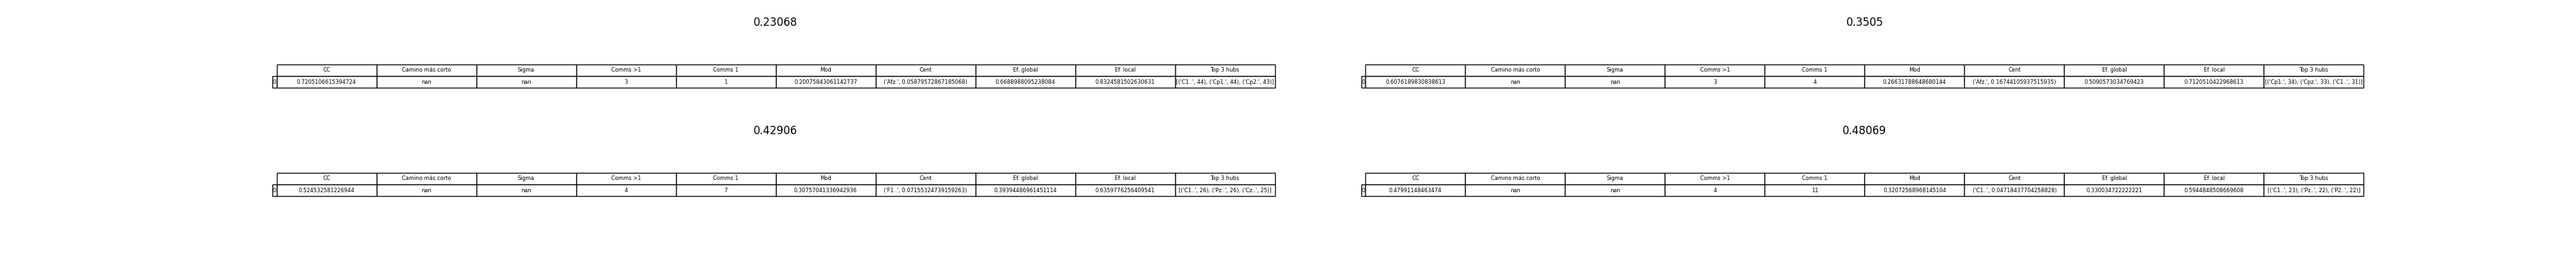

In [25]:
#Opciones de umbral: p75 de p25, media, p30 del p75, mediana de la p75

umbrales = [0.23068, 0.35050, 0.42906, 0.48069]
fig2 = plt.figure(figsize=(10,10))
axes = [fig2.add_subplot(2, 2, 1),
        fig2.add_subplot(2, 2, 2),
       fig2.add_subplot(2, 2, 3),
       fig2.add_subplot(2, 2, 4)]
i = 0
fig3, axes3 = plt.subplots(2,2, figsize=(40,4))
for umbral in umbrales:
    ensayo = capsula(ensayo4,umbral,0.75)
    sns.heatmap(ensayo, ax = axes[i])
    axes[i].set_title(str(umbral))
    i += 1

posiciones = [(0,0),(0,1),(1,0),(1,1)]
for umbral, (j,k) in zip(umbrales,posiciones):
    ensayo = capsula(ensayo4,umbral,0.75)
    (df_m, clust_coeff_, path_length_, small_world_sigma_, communities_, 
    modularity_, betwenness_, global_eff_, local_eff_, degree_dict_) = metricas(ensayo)
    axes3[j][k].axis('off')  # desactiva los ejes
    tabla = axes3[j][k].table(
        cellText=df_m.values,
        rowLabels=df_m.index,
        colLabels=df_m.columns,
        cellLoc='center',
        loc='center'
    )
    tabla.auto_set_font_size(False)
    tabla.set_fontsize(6)
    tabla.scale(1.1, 1.1)
    axes3[j][k].set_title(str(umbral))

### Umbral - Ensayo 4
Analizando los mapas de calor, número de comunidades, cantidad de nodo en esas comunidades, y la distribución topográfica de las conexiones se eligió la **mediana del percentil 75** como el umbral más adecuado para el **ensayo 4**. Esto es porque se busca el umbral que no pierda información, que preserve las características esperadas de conectividad y reduzca el ruido (conexiones poco significativas). Se optó por la mediana ya que **los percentiles 75 siguen una distribución normal (p>0.05 en Shapiro-Wilk)** y daba mejores resultados que la media. 


Con este umbral **(0.48069)** se observan muy claramente una comunidad o **red precentral(azul)** y una **postcentral(rojo)**, además que reduce la creación excesiva de comunidades de nodo único (mejor balance entre comunidades muy grandes y muy pequeñas).


El surco central es una fisura que divide longitudinalmente al cerebro en dos mitades. El giro precentral es una sección de la corteza que incluye, principalmente, a la corteza motora (encargada de iniciar el movimiento) mientras que el giro post central incluye la corteza somatosensorial (que recibe información de la posición y tacto sobre el cuerpo). 


Este umbral hace sentido ya que en la **red postcentral** que aparece se observa una **muy alta conexión de áreas occipitales (de procesamiento visual) entre ellas, y con áreas parietales (corteza somatosensorial)**. Esto se intuye como la **creación de una imagen mental y sensación imaginaria**, mientras que en la **red precentral** se conectan áreas frontales (toma de decisiones) y áreas precentrales (corteza motora), que se asume es por la **imaginación del movimiento**. De manera notoria, la **pequeña red precentral** presente en el esnsayo anterior está **ausente** en este.

### Gráficas de Ensayo 4 con el umbral elegido (0.48069)

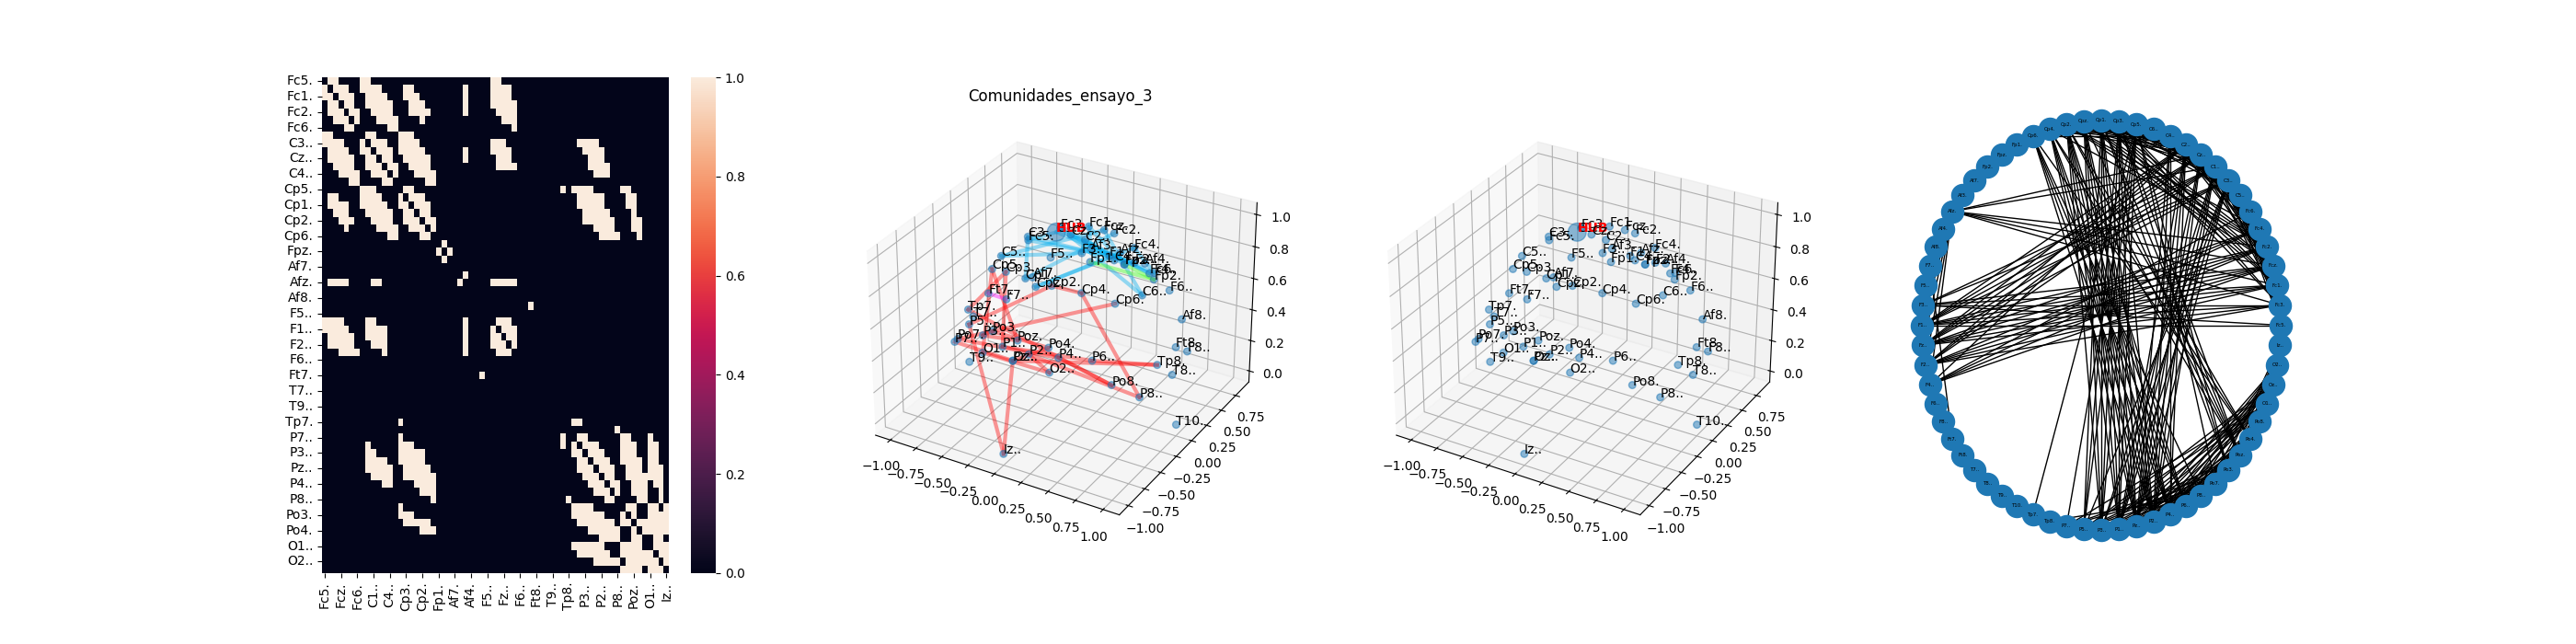

In [26]:
ensayo4_f = capsula(ensayo4,0.48069,0.75)
(df_m, clust_coeff_, path_length_, small_world_sigma_, communities_4, 
    modularity_, betwenness_4, global_eff_, local_eff_, degree_dict_) = metricas(ensayo4_f)
fig = plt.figure(figsize=(28,7))
axes = [fig.add_subplot(1, 4, 1),
        fig.add_subplot(1, 4, 2, projection='3d'),
       fig.add_subplot(1, 4, 3, projection='3d'),
       fig.add_subplot(1, 4, 4)]
hub = betwenness_4[0]
sns.heatmap(ensayo4_f, ax = axes[0])
grafcomm(communities_4, hub, coord, axes[1])
graf3d(hub, coord, axes[2])
graf2d(ensayo4_f, axes[3])

## Ensayo 5

C:\Users\Juan\Documents\GitHub\Neurociencias-2026-1\S06_proyecto\modulo.py:79: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  estadisticos = estadisticos.applymap(lambda x: f"{x:.5f}" if isinstance(x,(float,int)) else x)


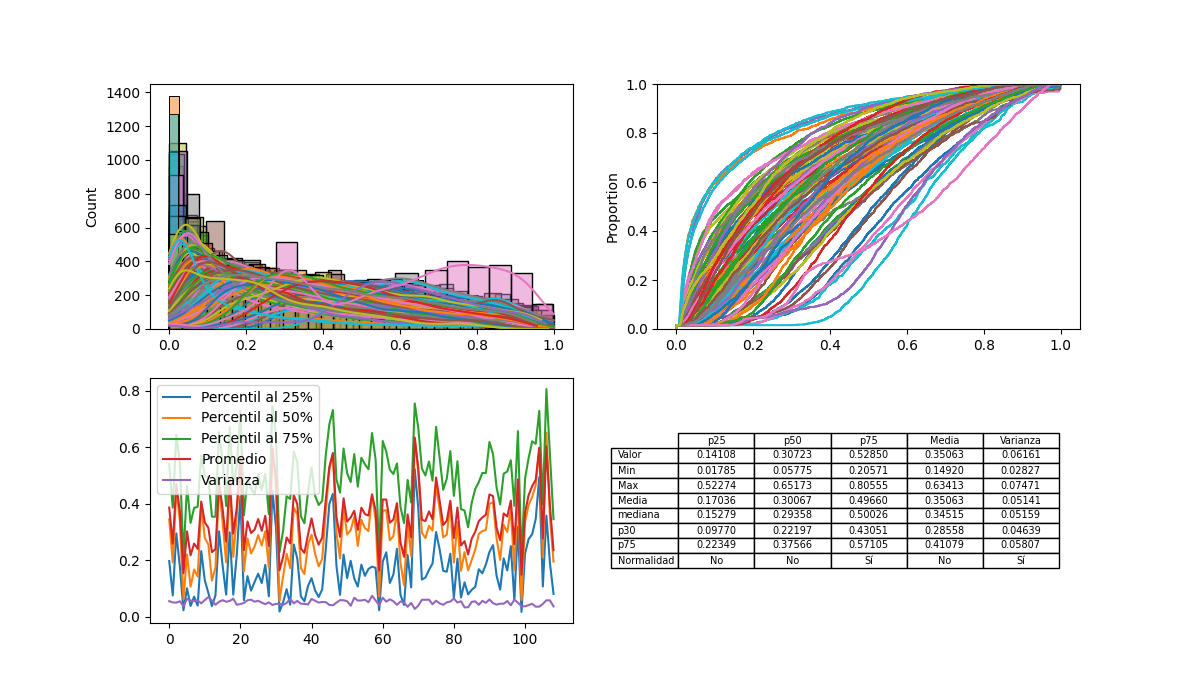

In [27]:
ensayo5 = lista_dfs(e5)
estadisticos_df(ensayo5)

C:\Users\Juan\AppData\Local\Temp\ipykernel_9676\1910155763.py:10: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig3, axes3 = plt.subplots(2,2, figsize=(40,4))


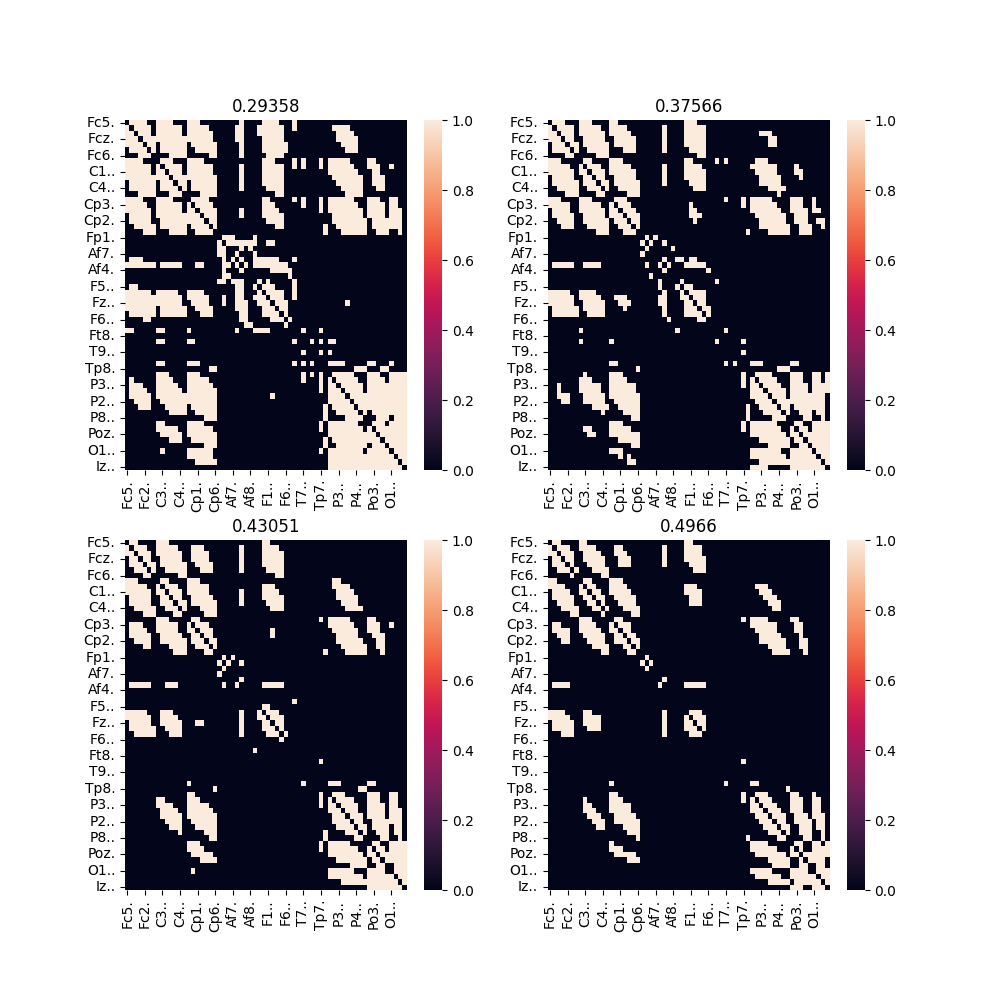

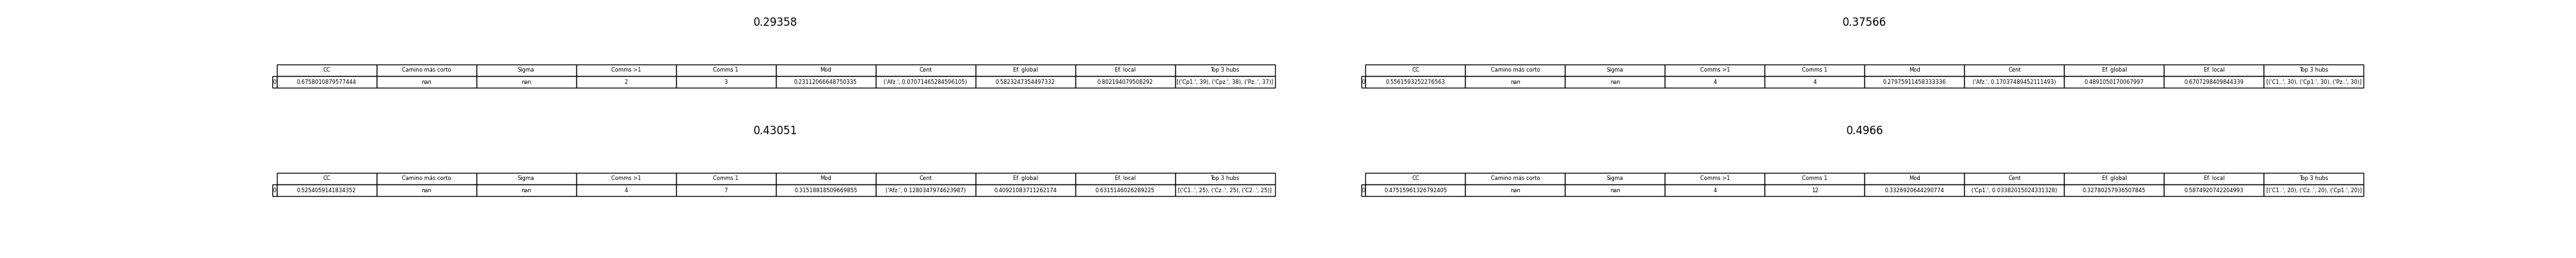

In [28]:
#Opciones de umbral: mediana del p50, p75 de la p50, p30 de la p75, media de la p75

umbrales = [0.29358, 0.37566, 0.43051, 0.49660]
fig2 = plt.figure(figsize=(10,10))
axes = [fig2.add_subplot(2, 2, 1),
        fig2.add_subplot(2, 2, 2),
       fig2.add_subplot(2, 2, 3),
       fig2.add_subplot(2, 2, 4)]
i = 0
fig3, axes3 = plt.subplots(2,2, figsize=(40,4))
for umbral in umbrales:
    ensayo = capsula(ensayo5,umbral,0.75)
    sns.heatmap(ensayo, ax = axes[i])
    axes[i].set_title(str(umbral))
    i += 1

posiciones = [(0,0),(0,1),(1,0),(1,1)]
for umbral, (j,k) in zip(umbrales,posiciones):
    ensayo = capsula(ensayo5,umbral,0.75)
    (df_m, clust_coeff_, path_length_, small_world_sigma_, communities_, 
    modularity_, betwenness_, global_eff_, local_eff_, degree_dict_) = metricas(ensayo)
    axes3[j][k].axis('off')  # desactiva los ejes
    tabla = axes3[j][k].table(
        cellText=df_m.values,
        rowLabels=df_m.index,
        colLabels=df_m.columns,
        cellLoc='center',
        loc='center'
    )
    tabla.auto_set_font_size(False)
    tabla.set_fontsize(6)
    tabla.scale(1.1, 1.1)
    axes3[j][k].set_title(str(umbral))

### Umbral - Ensayo 5
Analizando los mapas de calor, número de comunidades, cantidad de nodo en esas comunidades, y la distribución topográfica de las conexiones se eligió el **percentil 30 del percentil 75** como el umbral más adecuado para el **ensayo 5**. Esto es porque se busca el umbral que no pierda información, que preserve las características esperadas de conectividad y reduzca el ruido (conexiones poco significativas).


Con este umbral **(0.43051)** se observan muy claramente una comunidad o **red precentral(azul)** y una **postcentral(rojo)**, y se evita que la **eficiencia global y el coeficiente de clustering** llegen a valores tan bajos como con un umbral más alto, además que las comunidades mantienen una **coherencia esperada**.


El surco central es una fisura que divide longitudinalmente al cerebro en dos mitades. El giro precentral es una sección de la corteza que incluye, principalmente, a la corteza motora (encargada de iniciar el movimiento) mientras que el giro post central incluye la corteza somatosensorial (que recibe información de la posición y tacto sobre el cuerpo). 


Este umbral hace sentido ya que en la **red postcentral** que aparece se observa una muy alta conexión de áreas occipitales (de procesamiento visual), entre ellas, y con áreas parietales (corteza somatosensorial). Esto se intuye como la **retroalimentación visual del movimiento**, mientras que en la **red precentral** se conectan áreas frontales (toma de decisiones) y áreas precentrales (corteza motora), que se asume es por la **ejecución del movimiento**. La **pequeña comunidad en la parte precentral izquierda** presente en el ensayo 3 está **ausente**. Esto podría ser ya que no hay tanta dominancia en el movimiento de pies (ensayo 5) como en el de manos (ensayo 3).

### Gráficas de Ensayo 5 con el umbral elegido (0.43051)

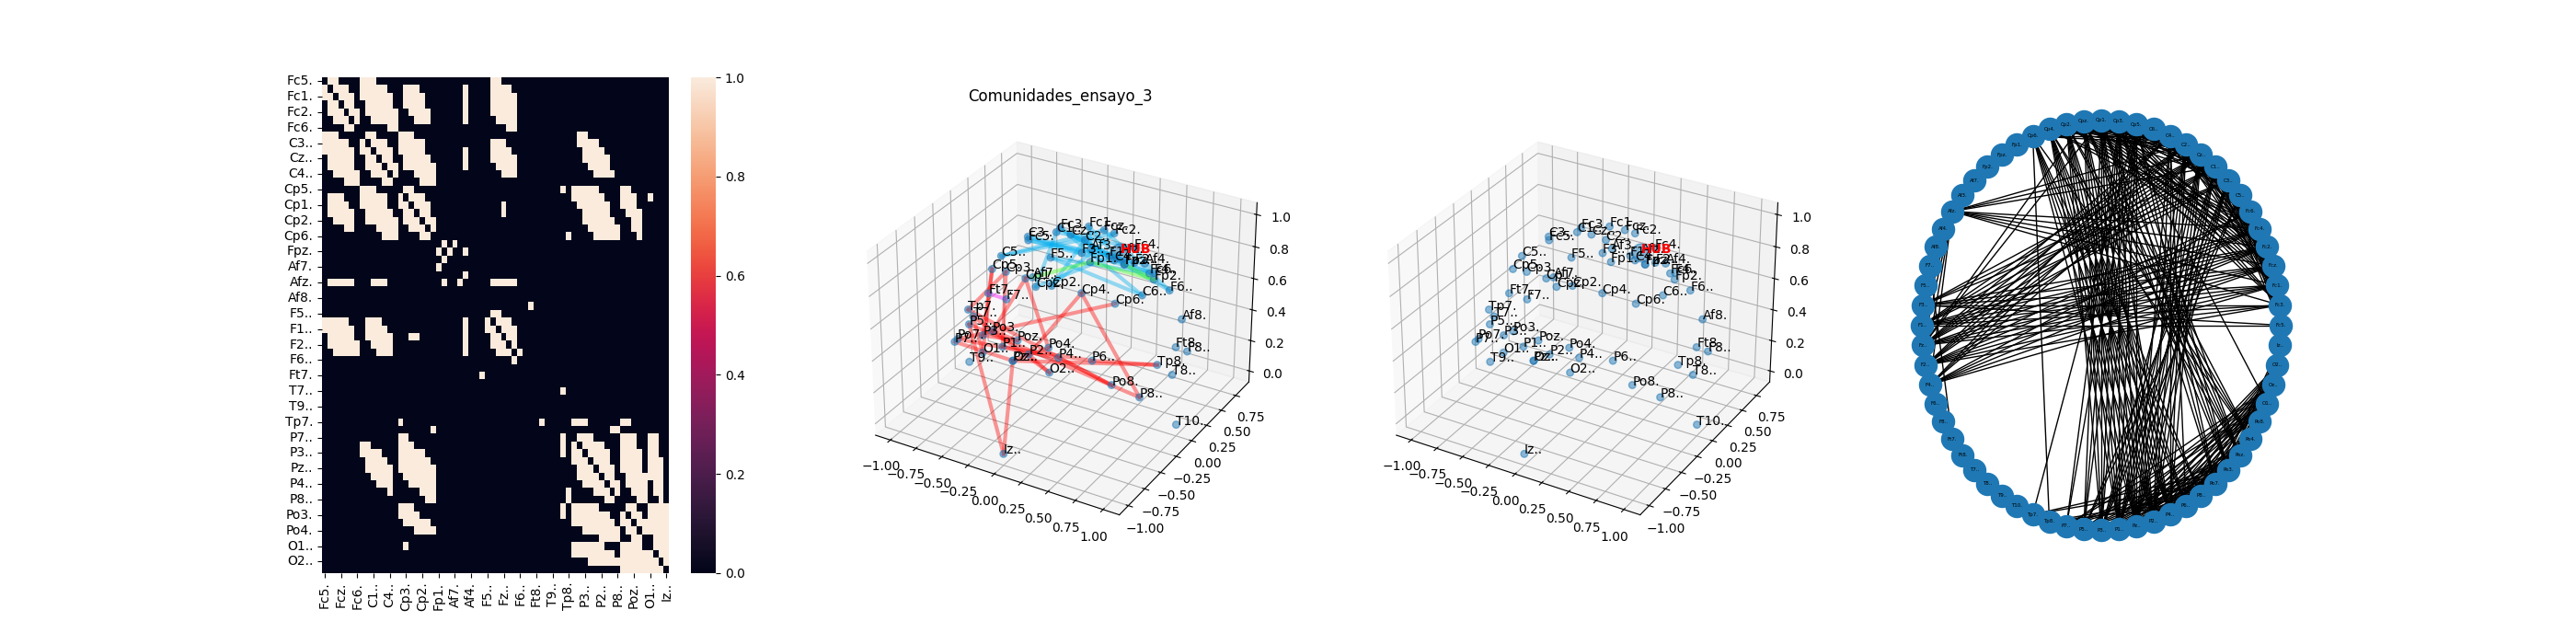

In [33]:
ensayo5_f = capsula(ensayo5,0.43051,0.75)

(df_m, clust_coeff_, path_length_, small_world_sigma_, communities_5, 
    modularity_, betwenness_5, global_eff_, local_eff_, degree_dict_) = metricas(ensayo5_f)

fig = plt.figure(figsize=(28,7))
axes = [fig.add_subplot(1, 4, 1),
        fig.add_subplot(1, 4, 2, projection='3d'),
       fig.add_subplot(1, 4, 3, projection='3d'),
       fig.add_subplot(1, 4, 4)]
hub5 = betwenness_5[0]
sns.heatmap(ensayo5_f, ax = axes[0])
grafcomm(communities_5, hub5, coord, axes[1])
graf3d(hub5, coord, axes[2])
graf2d(ensayo5_f, axes[3])

## Ensayo 6

C:\Users\Juan\Documents\GitHub\Neurociencias-2026-1\S06_proyecto\modulo.py:79: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  estadisticos = estadisticos.applymap(lambda x: f"{x:.5f}" if isinstance(x,(float,int)) else x)


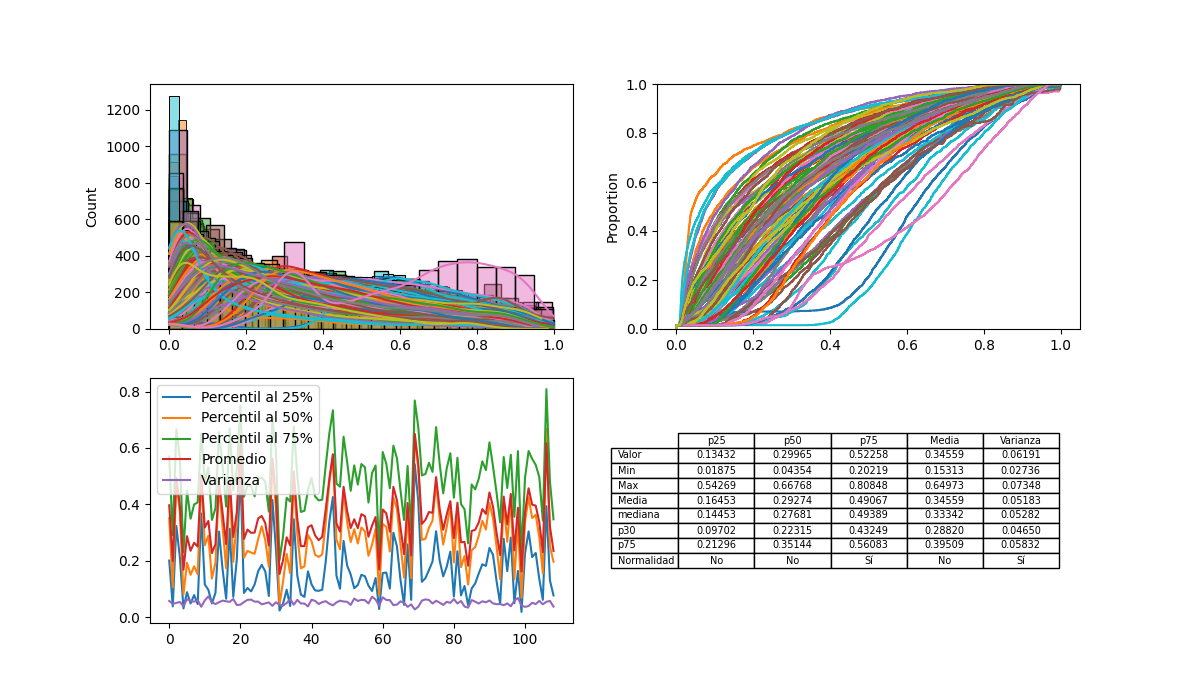

In [35]:
ensayo6 = lista_dfs(e6)
estadisticos_df(ensayo6)

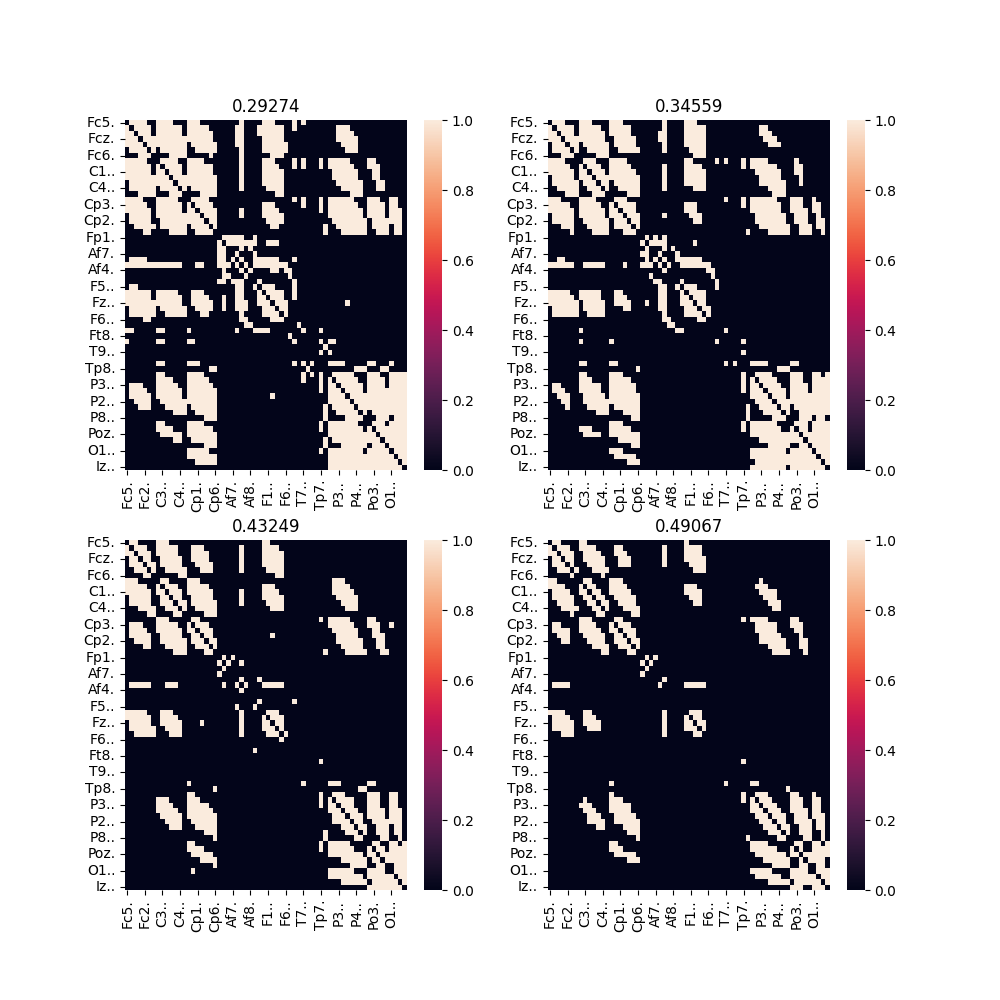

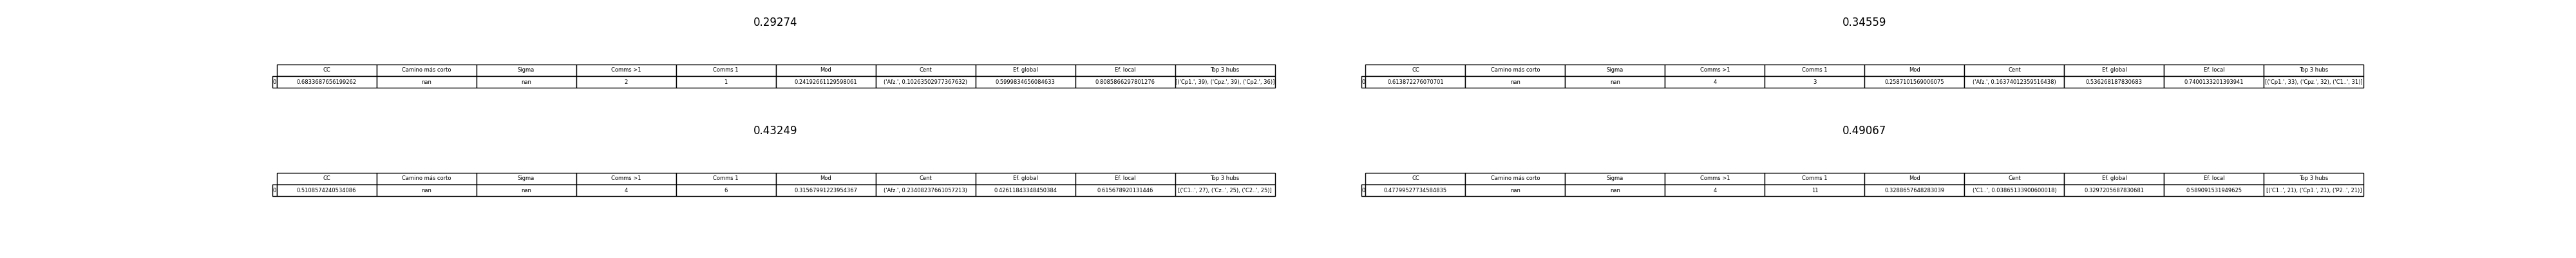

In [36]:
#Opciones de umbral: media del p50, media, p30 de la p75, media de la p75

umbrales = [0.29274, 0.34559, 0.43249, 0.49067]
fig2 = plt.figure(figsize=(10,10))
axes = [fig2.add_subplot(2, 2, 1),
        fig2.add_subplot(2, 2, 2),
       fig2.add_subplot(2, 2, 3),
       fig2.add_subplot(2, 2, 4)]
i = 0
fig3, axes3 = plt.subplots(2,2, figsize=(40,4))
for umbral in umbrales:
    ensayo = capsula(ensayo6,umbral,0.75)
    sns.heatmap(ensayo, ax = axes[i])
    axes[i].set_title(str(umbral))
    i += 1

posiciones = [(0,0),(0,1),(1,0),(1,1)]
for umbral, (j,k) in zip(umbrales,posiciones):
    ensayo = capsula(ensayo6,umbral,0.75)
    (df_m, clust_coeff_, path_length_, small_world_sigma_, communities_, 
    modularity_, betwenness_, global_eff_, local_eff_, degree_dict_) = metricas(ensayo)
    axes3[j][k].axis('off')  # desactiva los ejes
    tabla = axes3[j][k].table(
        cellText=df_m.values,
        rowLabels=df_m.index,
        colLabels=df_m.columns,
        cellLoc='center',
        loc='center'
    )
    tabla.auto_set_font_size(False)
    tabla.set_fontsize(6)
    tabla.scale(1.1, 1.1)
    axes3[j][k].set_title(str(umbral))

### Umbral - Ensayo 6
Analizando los mapas de calor, número de comunidades, cantidad de nodo en esas comunidades, y la distribución topográfica de las conexiones se eligió el **percentil 30 del percentil 75** como el umbral más adecuado para el **ensayo 6**. Esto es porque se busca el umbral que no pierda información, que preserve las características esperadas de conectividad y reduzca el ruido (conexiones poco significativas).


Con este umbral **(0.43249)** se observan muy claramente una comunidad o **red precentral(roja, en este caso)** y una **postcentral(azul)**, además de una **eficiencia global y coeficiente de clustering** que no llegan a valores tan bajos como con el umbral más alto, y un nodo particular que mantiene un **alto grado de centralidad** (característica esperada en una red cerebral).


El surco central es una fisura que divide longitudinalmente al cerebro en dos mitades. El giro precentral es una sección de la corteza que incluye, principalmente, a la corteza motora (encargada de iniciar el movimiento) mientras que el giro post central incluye la corteza somatosensorial (que recibe información de la posición y tacto sobre el cuerpo). 


Este umbral hace sentido ya que en la **red postcentral** que aparece se observa una **muy alta conexión de áreas occipitales (de procesamiento visual) entre ellas, y con áreas parietales (corteza somatosensorial)**. Esto se intuye como la **creación de una imagen mental y sensación imaginaria**, mientras que en la **red precentral** se conectan áreas frontales (toma de decisiones) y áreas precentrales (corteza motora), que se asume es por la **imaginación del movimiento**. Hay una **pequeña red en morado** pero no parece compartir las características con las descritas anteriormente (no llega a la línea central), pero algo interesante es que las **áreas visuales están más interconectadas** que en las condiciones de movimiento sin imaginación.

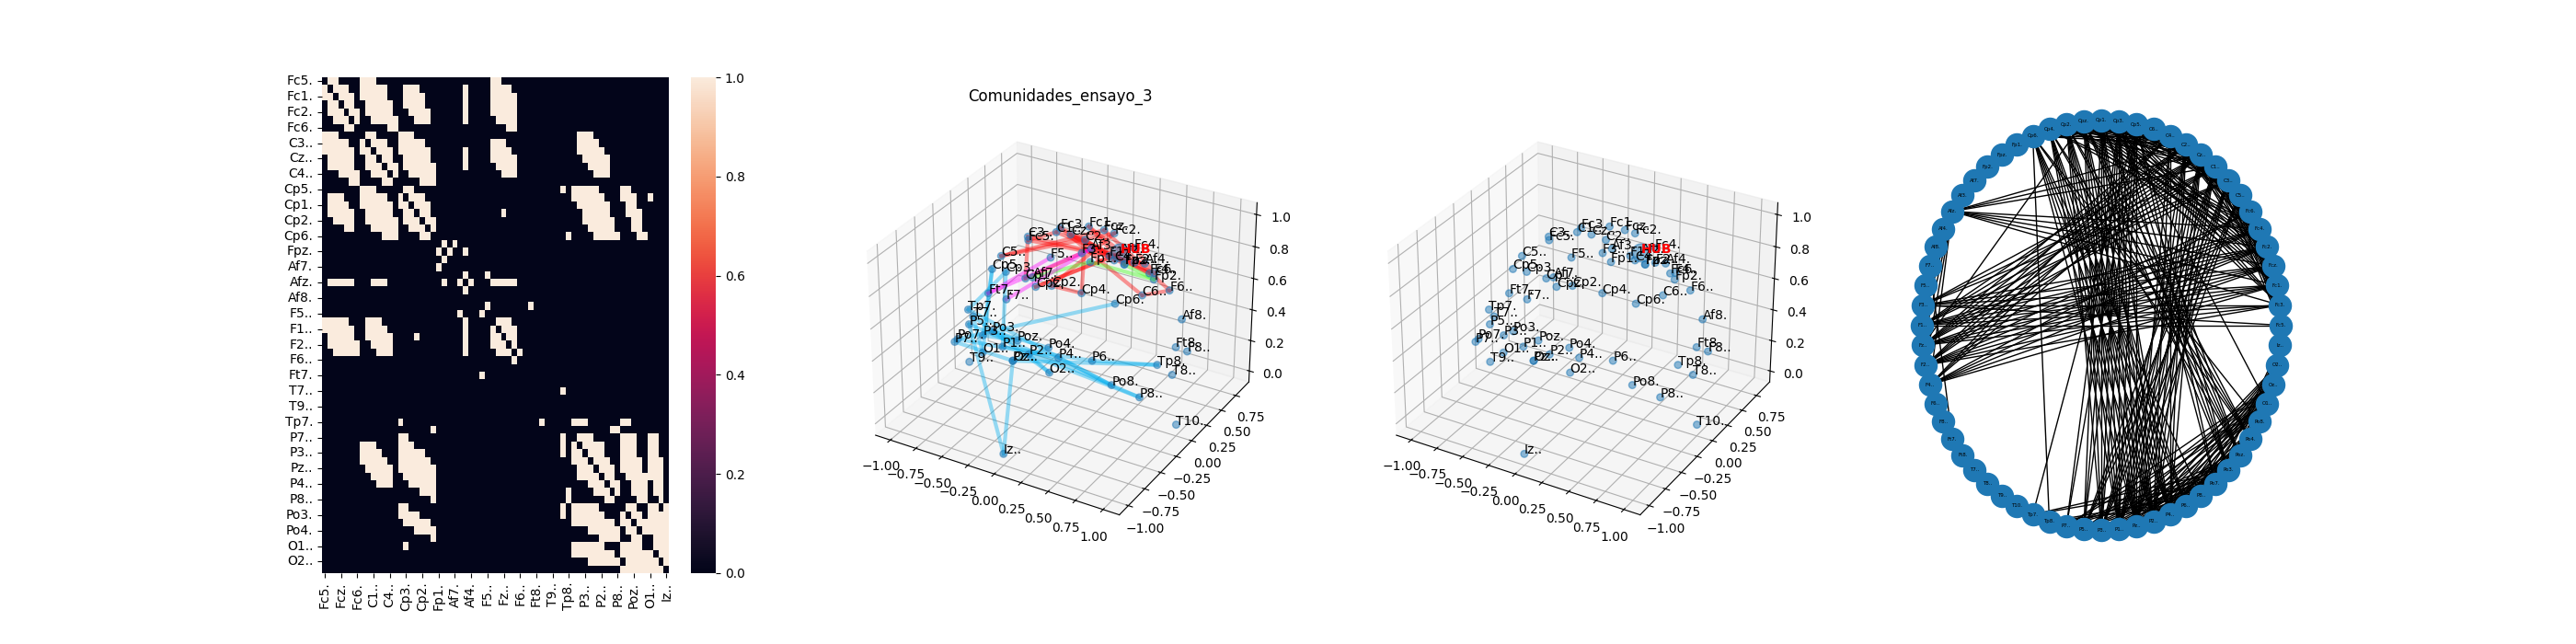

In [39]:
ensayo6_f = capsula(ensayo6,0.43249,0.75)

(df_m, clust_coeff_, path_length_, small_world_sigma_, communities_6, 
    modularity_, betwenness_6, global_eff_, local_eff_, degree_dict_) = metricas(ensayo6_f)

fig = plt.figure(figsize=(28,7))
axes = [fig.add_subplot(1, 4, 1),
        fig.add_subplot(1, 4, 2, projection='3d'),
       fig.add_subplot(1, 4, 3, projection='3d'),
       fig.add_subplot(1, 4, 4)]
hub6 = betwenness_6[0]
sns.heatmap(ensayo6_f, ax = axes[0])
grafcomm(communities_6, hub6, coord, axes[1])
graf3d(hub6, coord, axes[2])
graf2d(ensayo6_f, axes[3])

## Conclusión

Los **umbrales** se mantuvieron en **valores cercanos** alrededor de los ensayos. Esto destaca junto con la evidencia de las **mismas redes** encontradas en tareas de movimiento e imaginación. Esto es positivo ya que habla de una **activación común** en ambas de estas situaciones, lo cuál es útil para el entrenamiento de interfaces cerebro-máquina o terapias de rehabilitación de un miembro. Fué interesante también observar la **dinámica de las métricas de los grafos**, que también seguían un comportamiento similar, y el encontrar **redes pequeñas** que dieron lugar a hacer hipótesis acerca de las **características (dominancia manual) de la población** usada.